# Basic Training Loop for MIS problem inference
This note book aims to give a simple example of how to create a simple training loop for MIS solution prediction. It is structured in the following manner:
- Instance generation:
  - Labeling: how to solve the problem and create labels for training
  - Creating the Bipartite graph that represents the problem
- Model definition
- Training loop


In [1]:
import sys
sys.path.insert(0,"..")

import networkx as nx
import torch_geometric as tg
import torch
import numpy as np
import bpropy
import matplotlib.pyplot as plt
import time

## Instance generation
In this section we will review the process of generating MIS instances with `bpropy` and `networkx` and how to solve them. First we will import the module `bpropy.co.mis` to have acces to the `MIS` class definition.

In [2]:
from bpropy.co.mis import MIS

Now lets create a graph using the Erdos-Renyi generation method implemented in `networkx`

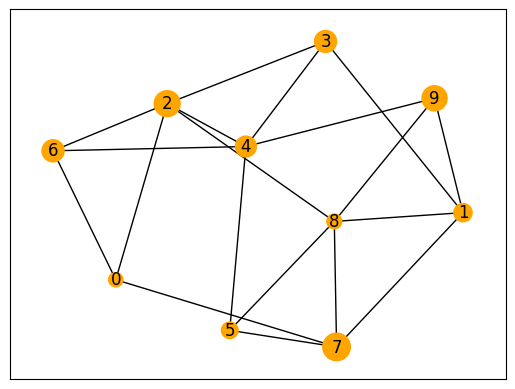

In [3]:
g = nx.generators.random_graphs.erdos_renyi_graph(10, 0.50)
pos = nx.layout.kamada_kawai_layout(g)
# node weights
w = np.random.rand(10)
nx.draw_networkx(g, pos=pos, node_color="orange", node_size=100+300*w)

Now we can create a MIS instance with

In [4]:

pb = MIS(g, weights=w)

We can solve the problem by calling the `MIS.solve` method

In [5]:
sol = pb.solve(solver="scipy")
print(sol.x)

[-0. -0. -0.  1.  0. -0.  1.  1.  0.  1.]


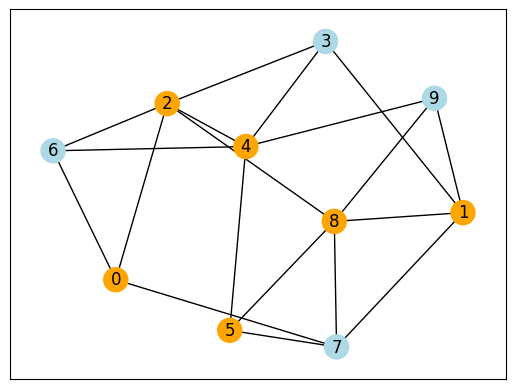

In [6]:
node_color = []
for n in pb.g.nodes():
    if sol.x[n] == 1:
        node_color.append("lightblue")
    else:
        node_color.append("orange")
nx.draw_networkx(pb.g, node_color=node_color, pos=pos)

## Dataset generation
We will create a train dataset of 100 graphs with solutions, and a test set with 10 graphs and solutions. First lets define a `generate_instance_and_solution` function to generate a random MIS and compute its solutions.

In [7]:
def generate_instance_and_solution(n=10, p=0.5):
    g = nx.generators.random_graphs.erdos_renyi_graph(n, p)
    pb = MIS(g, weights = np.random.rand(n))
    sol = pb.solve(solver="scipy")
    return (pb, sol)

In [8]:
train_dataset = [generate_instance_and_solution() for _ in range(100)]
validation_dataset = [generate_instance_and_solution() for _ in range(10)]
test_dataset = [generate_instance_and_solution() for _ in range(10)]

To use with `torch_geometric` GNNs we need to convert the `networkx` graphs and solutions to `torch_geometric.data.Data` objects. The `torch_geometric.utils.from_networkx` function transforms a `networkx.Graph` object to `torch_geometric.data.Data` object and fills in its `edge_index` and `num_nodes` attributes. We will manualy add the features `data.x` which represent the node weights and `data.y` representing the node labels (or targets).

In [9]:
def mis_and_solution_to_data(pb, sol):
    data = tg.utils.from_networkx(pb.g)
    data.x = torch.from_numpy(pb.w).unsqueeze(-1).to(torch.float)
    data.y = torch.from_numpy(sol.x).to(torch.float).unsqueeze(-1)
    
    return data
data = mis_and_solution_to_data(*train_dataset[0])
print(data)

Data(edge_index=[2, 44], num_nodes=10, x=[10, 1], y=[10, 1])


Now apply this function to all pairs of (problem,solution) in `train_dataset` and `test_dataset`

In [10]:
train_data = [mis_and_solution_to_data(pb,sol) for (pb,sol) in train_dataset]
validation_data = [mis_and_solution_to_data(pb,sol) for (pb,sol) in validation_dataset]
test_data = [mis_and_solution_to_data(pb,sol) for (pb,sol) in test_dataset]

In [11]:
print(train_data[0].x)

tensor([[0.6171],
        [0.6991],
        [0.3835],
        [0.5341],
        [0.7036],
        [0.1994],
        [0.3644],
        [0.9343],
        [0.5009],
        [0.8110]])


## Defining the predictor
Lets now create a GNN with `torch_geometric`. The model is composed of 3 modules:
 - a GCNConv layer that transforms the 1-dimension input features into 2-dimensional vectors
 - a ELU non-linear activation function
 - a GCNConv layer that retransforms our 2-dimension features to 1-dimension scores

In [12]:
model = tg.nn.Sequential("x, edge_index", [
    (tg.nn.GCNConv(1, 2), "x, edge_index -> x"),
    torch.nn.ELU(),
    (tg.nn.GCNConv(2, 1), "x, edge_index -> x")
])

Let's test our model on the first `Data` object in our training dataset and see its output

In [13]:
model(train_data[0].x, train_data[0].edge_index)

tensor([[0.0157],
        [0.0206],
        [0.0163],
        [0.0174],
        [0.0170],
        [0.0149],
        [0.0227],
        [0.0215],
        [0.0190],
        [0.0188]], grad_fn=<AddBackward0>)

Note that we can access individual parameters of the model, these are the parameters we want to train through supervised learning

In [14]:
[p for p in model.parameters()]

[Parameter containing:
 tensor([0., 0.], requires_grad=True),
 Parameter containing:
 tensor([[-0.0583],
         [ 0.0697]], requires_grad=True),
 Parameter containing:
 tensor([0.], requires_grad=True),
 Parameter containing:
 tensor([[-0.2696,  0.2401]], requires_grad=True)]

We can also access the individual sub-modules of `model` (in our case there are 3: `module_0` is the first GCNConv, `module_1` is the ELU activation, and `module_2` is the final GCNConv layer)

In [15]:
model.module_0(train_data[0].x, train_data[0].edge_index)

tensor([[-0.0264,  0.0316],
        [-0.0410,  0.0490],
        [-0.0302,  0.0361],
        [-0.0283,  0.0338],
        [-0.0349,  0.0417],
        [-0.0264,  0.0315],
        [-0.0421,  0.0503],
        [-0.0382,  0.0456],
        [-0.0324,  0.0386],
        [-0.0331,  0.0396]], grad_fn=<AddBackward0>)

Let's retrieve the parameters of the first GCNConv layer

In [16]:
p_list = list(model.module_0.parameters())
bias = p_list[0]
weights = p_list[1]

model.module_0(train_data[0].x, train_data[0].edge_index) / torch.transpose(weights,0,1)

tensor([[0.4531, 0.4531],
        [0.7033, 0.7033],
        [0.5182, 0.5182],
        [0.4851, 0.4851],
        [0.5983, 0.5983],
        [0.4529, 0.4529],
        [0.7219, 0.7219],
        [0.6551, 0.6551],
        [0.5548, 0.5548],
        [0.5681, 0.5681]], grad_fn=<DivBackward0>)

## Basic training loop
Now lets implement a simple training loop to learn the parameters of our `model`. First step is to define a loss function

In [17]:
def loss(x_pred, x_target):
    return torch.nn.functional.binary_cross_entropy_with_logits(x_pred, x_target)

lambda_loss = lambda x_pred, x_target: torch.nn.functional.binary_cross_entropy_with_logits(x_pred, x_target)

Let's try our loss function

In [18]:
loss_val = loss(
    model(train_data[0].x, train_data[0].edge_index),
    train_data[0].y)
print("loss = ", loss_val)

loss =  tensor(0.6968, grad_fn=<BinaryCrossEntropyWithLogitsBackward0>)


Calling the `backward` function triggers the computation of the gradient by backpropagating the output along the computation tree. After calling `backward` the `grad` attribute of the model parameters are populated. The following shows the values of the gradients of the parameters of the `module_0` layer of our model.

In [19]:
print("Before backward bias.grad = ", bias.grad)
print("Before backward weights.grad = ", weights.grad)
loss_val.backward()
print("After backward bias.grad = ", bias.grad)
print("After backward weights.grad = ", weights.grad)

Before backward bias.grad =  None
Before backward weights.grad =  None
After backward bias.grad =  tensor([-0.0517,  0.0476])
After backward weights.grad =  tensor([[-0.0298],
        [ 0.0275]])


To train our model we want to follow the opposite direction of the gradient of the loss function with regard to the parameters of the model. Lets try it on our train data

In [20]:
step_size = 0.1
loss_values = []
for epoch in range(50):
    epoch_loss = []
    for data in train_data:
        model.zero_grad()
        x_pred = model(data.x, data.edge_index)
        x_target = data.y
        loss_value = loss(x_pred, x_target)
        epoch_loss.append(loss_value.item()) # set aside the value of the loss for later computation and tracking
        # populate the gradient
        loss_value.backward()
        with torch.no_grad():
            for p in model.parameters():
                p += - step_size * p.grad
    loss_values.append(np.mean(epoch_loss))
    print(f"Epoch {epoch} loss {np.mean(epoch_loss)}")
    

Epoch 0 loss 0.6658381301164628
Epoch 1 loss 0.6574017030000686
Epoch 2 loss 0.6556970781087875
Epoch 3 loss 0.6536806130409241
Epoch 4 loss 0.6513067704439163
Epoch 5 loss 0.6486221224069595
Epoch 6 loss 0.6456893730163574
Epoch 7 loss 0.6425723052024841
Epoch 8 loss 0.6393283021450042
Epoch 9 loss 0.6360056632757187
Epoch 10 loss 0.6326434075832367
Epoch 11 loss 0.629272358417511
Epoch 12 loss 0.6259166353940964
Epoch 13 loss 0.6225949907302857
Epoch 14 loss 0.6193221318721771
Epoch 15 loss 0.6161096024513245
Epoch 16 loss 0.6129666513204575
Epoch 17 loss 0.6099007099866867
Epoch 18 loss 0.6069178408384324
Epoch 19 loss 0.6040229886770249
Epoch 20 loss 0.601220178604126
Epoch 21 loss 0.5985126417875289
Epoch 22 loss 0.5959027397632599
Epoch 23 loss 0.5933921322226524
Epoch 24 loss 0.5909817036986351
Epoch 25 loss 0.5886715888977051
Epoch 26 loss 0.5864611586928368
Epoch 27 loss 0.5843491801619529
Epoch 28 loss 0.582333699464798
Epoch 29 loss 0.5804122251272201
Epoch 30 loss 0.5785817

We can visualise the loss datam

Text(0, 0.5, 'Loss')

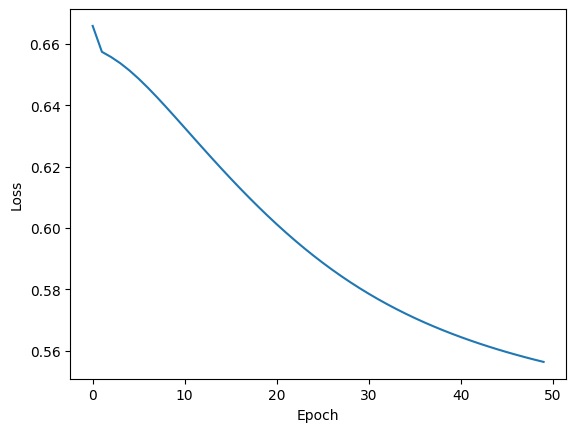

In [21]:
plt.figure()
plt.plot(loss_values)
plt.xlabel("Epoch")
plt.ylabel("Loss")

The training loop can be made more efficient by using optimizers from the `torch.optim` module such as the well known Adam optimizer. Start by initializing a new model.


In [22]:
model = tg.nn.Sequential("x, edge_index", [
    (tg.nn.GCNConv(1, 2), "x, edge_index -> x"),
    torch.nn.ELU(),
    (tg.nn.GCNConv(2, 1), "x, edge_index -> x")
])

In [23]:
step_size = 0.1

optimizer = torch.optim.Adam(model.parameters(), lr=step_size)

adam_loss_values = []
for epoch in range(50):
    epoch_loss = []
    for data in train_data:
        optimizer.zero_grad()
        x_pred = model(data.x, data.edge_index)
        x_target = data.y
        loss_value = loss(x_pred, x_target)
        epoch_loss.append(loss_value.item()) # set aside the value of the loss for later computation and tracking
        # populate the gradient
        loss_value.backward()
        optimizer.step()
    adam_loss_values.append(np.mean(epoch_loss))
    print(f"Epoch {epoch} loss {np.mean(epoch_loss)}")

Epoch 0 loss 0.6393668055534363
Epoch 1 loss 0.6096319472789764
Epoch 2 loss 0.5900162613391876
Epoch 3 loss 0.5766218355298043
Epoch 4 loss 0.5671122777462005
Epoch 5 loss 0.5602993595600129
Epoch 6 loss 0.5553313925862312
Epoch 7 loss 0.551653558909893
Epoch 8 loss 0.5488786348700523
Epoch 9 loss 0.5467641314864159
Epoch 10 loss 0.545139339864254
Epoch 11 loss 0.5438832375407219
Epoch 12 loss 0.5429095467925071
Epoch 13 loss 0.5421514156460762
Epoch 14 loss 0.5415593254566192
Epoch 15 loss 0.5410965079069138
Epoch 16 loss 0.5407341462373734
Epoch 17 loss 0.5404505106806755
Epoch 18 loss 0.5402290916442871
Epoch 19 loss 0.5400562527775764
Epoch 20 loss 0.5399215635657311
Epoch 21 loss 0.539816998243332
Epoch 22 loss 0.5397363445162773
Epoch 23 loss 0.539674597978592
Epoch 24 loss 0.5396276912093163
Epoch 25 loss 0.5395926508307457
Epoch 26 loss 0.5395669630169868
Epoch 27 loss 0.5395485645532608
Epoch 28 loss 0.5395359709858895
Epoch 29 loss 0.5395278266072273
Epoch 30 loss 0.53952312

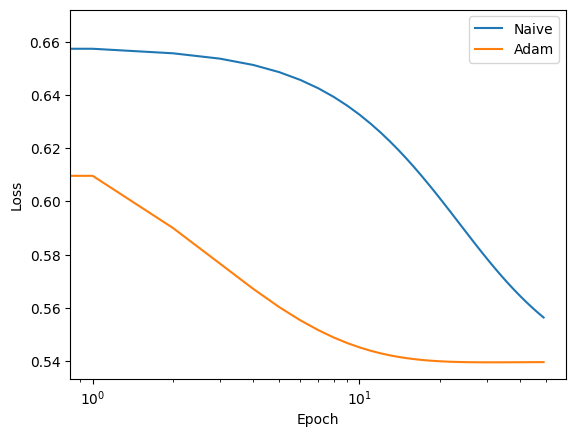

In [24]:
plt.figure()
plt.plot(loss_values, label="Naive")
plt.plot(adam_loss_values, label="Adam")
plt.xscale("log")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()

## Adding a validation score
We are interested in solving the optimization problem, as such a good validation metric (variations of which indicate that the model is getting better at the task we want it to solve) is the **optimality gap**. Given a maximization problem $(P)$, $x^*$ the optimal solution and $x$ a candidate solution. We have that necessarily $c(x^*) \geq c(x)$. 

The optimiality gap of $x$, denoted by $\mathcal{O}(x^*,x)$ is defined : $\mathcal{O}(x^*,x) = \frac{ c(x^*) - c(x)}{c(x^*)}$

In [31]:
def optimality_gap(x_star, x, c):
    return (torch.dot(x_star, c) - torch.dot(x,c)) / torch.dot(x_star, c)

Try calculating the optimality gap for problem `pb` between the solution given by using `solve` without specifying the solver and a `greedy` solution. 

First solve with B&B

In [32]:
t_default = time.time()
sol_default = pb.solve(solver="solver") # solve with branch-and-bound
t_default = time.time() - t_default
val_default = np.dot(sol_default.x, pb.w)
print(f"Default solver time = {t_default}s, objective = {val_default}")

Default solver time = 0.00798487663269043s, objective = 2.1162024999257425


Now solve with greedy

In [33]:
t_greedy = time.time()
sol_greedy = pb.greedy() # solve with branch-and-bound
t_greedy = time.time() - t_greedy
val_greedy = np.dot(sol_greedy, pb.w)
print(f"Greedy solver time = {t_greedy}s, objective = {val_greedy}")

Greedy solver time = 0.0003275871276855469s, objective = 2.44427513962639


And the optimality gap

In [34]:
print("Optimality gap = ", optimality_gap(
    torch.from_numpy(sol_default.x), 
    torch.from_numpy(sol_greedy), 
    torch.from_numpy(pb.w)))

Optimality gap =  tensor(-0.1550, dtype=torch.float64)


Rather than solving the problem with an exact method such as B&B which can take an exponential amount of time for hard problems, our objective is to train the GNN to predict scores that can guide the greedy construction of a solution toward high quality solutions.

Note that it is obvious that such scores exist since taking $x^*$ as scores for our greedy procedure yields the optimal solution.

In [ ]:
model = tg.nn.Sequential("x, edge_index", [
    (tg.nn.GCNConv(1, 2), "x, edge_index -> x"),
    torch.nn.ELU(),
    (tg.nn.GCNConv(2, 1), "x, edge_index -> x")
])


step_size = 1e-5

optimizer = torch.optim.Adam(model.parameters(), lr=step_size)

adam_loss_values = []
adam_validation_values = []
for epoch in range(1000):
    epoch_loss = []
    for data in train_data:
        optimizer.zero_grad()
        x_pred = model(data.x, data.edge_index)
        x_target = data.y
        loss_value = loss(x_pred, x_target)
        epoch_loss.append(loss_value.item()) # set aside the value of the loss for later computation and tracking
        # populate the gradient
        loss_value.backward()
        optimizer.step()

    # validation step
    val_values = []
    with torch.no_grad():
        for ((pb,sol),data) in zip(validation_dataset, validation_data):
            scores = model(data.x, data.edge_index)
            x_target = data.y.flatten()
            x_pred = torch.from_numpy(pb.greedy(scores = scores)).to(torch.float)
            weights = torch.from_numpy(pb.w).to(torch.float)
            # optimality gap
            gap = optimality_gap(x_target.flatten(), x_pred, weights)
            val_values.append(gap)
    adam_loss_values.append(np.mean(epoch_loss))
    adam_validation_values.append(np.mean(val_values))
    print(f"Epoch {epoch} loss = {np.mean(epoch_loss)} val_gap = {np.mean(val_values)}")

Epoch 0 loss = 0.688185555934906 val_gap = 0.3150220513343811
Epoch 1 loss = 0.687953908443451 val_gap = 0.3150220513343811
Epoch 2 loss = 0.6877232068777084 val_gap = 0.3150220513343811
Epoch 3 loss = 0.6874936717748642 val_gap = 0.3150220513343811
Epoch 4 loss = 0.6872653478384018 val_gap = 0.3150220513343811
Epoch 5 loss = 0.6870382231473923 val_gap = 0.3150220513343811
Epoch 6 loss = 0.6868122851848603 val_gap = 0.3150220513343811
Epoch 7 loss = 0.6865875393152236 val_gap = 0.3150220513343811
Epoch 8 loss = 0.6863639599084854 val_gap = 0.3150220513343811
Epoch 9 loss = 0.6861415201425553 val_gap = 0.3150220513343811
Epoch 10 loss = 0.6859202438592911 val_gap = 0.3150220513343811
Epoch 11 loss = 0.685700073838234 val_gap = 0.3150220513343811
Epoch 12 loss = 0.6854810208082199 val_gap = 0.3150220513343811
Epoch 13 loss = 0.6852630853652955 val_gap = 0.3150220513343811
Epoch 14 loss = 0.6850462251901627 val_gap = 0.3150220513343811
Epoch 15 loss = 0.6848304545879365 val_gap = 0.315022

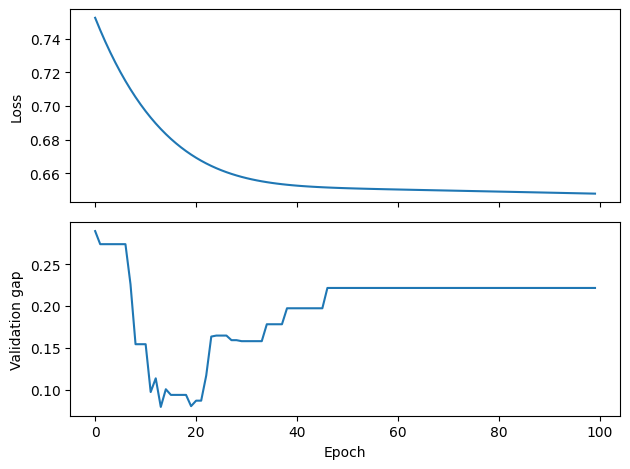

In [46]:
fig, ax = plt.subplots(2,1, sharex=True)
ax[0].plot(adam_loss_values)
ax[0].set_ylabel("Loss")
ax[1].plot(adam_validation_values)
ax[1].set_xlabel("Epoch")
ax[1].set_ylabel("Validation gap")
plt.tight_layout()